# Is this sequence of coin tosses real or fake?  

In the course we are presented with two coin toss "experiments", where a coin is tossed 300 times, and the result (heads, H, or tails, T) recorded. How do we know if the experiment is real or made up? This sort of analysis goes beyond AI and into things like [falsifying data in scientific research](https://casrai.org/guides/research-misconduct-case-studies), but in the course it is supplied as a way to figure out if AI wrote a piece of text.

Here I will reproduce the experiment used in the course, and calculate the probability that the data is real versus "made up".

## Experiment 1  
TTHHTHTTHTTTHTTTHTTTHTTHTHHTHHTHTHHTTTHHTHTHTTHTHH\
TTHTHHTHTTTHHTTHHTTHHHTHHTHTTHTHTTHHTHHHTTHTHTTTHH\
TTHTHTHTHTHTTHTHTHHHTTHTHTHHTHHHTHTHTTHTTHHTHTHTHT\
THHTTHTHTTHHHTHTHTHTTHTTHHTTHTHHTHHHTTHHTHTTHTHTHT\
HTHTHTHHHTHTHTHTHHTHHTHTHTTHTTTHHTHTTTHTHHTHHHHTTT\
HHTHTHTHTHHHTTHHTHTTTHTHHTHTHTHHTHTTHTTHTHHTHTHTTHT

## Experiment 2  
HTHHHTHTTHHTTTTTTTTHHHTTTHHTTTTHHTTHHHTTHTHTTTTTTH\
THTTTTHHHHTHTHTTHTTTHTTHTTTTHTHHTHHHHTTTTTHHHHTHHH\
TTTTHTHTTHHHHTHHHHHHHHTTHHTHHTHHHHHHHTTHTHTTTHHTTT\
THTHHTTHTTHTHTHTTHHHHHTTHTTTHTHTHHTTTTHTTTTTHHTHTH\
HHHTTTTHTHHHTHHTHTHTHTHHHTHTTHHHTHHHHHHTHHHTHTTTHH\
HTTTHHTHTTHHTHHHTHTTHTTHTTTHHTHTHTTTTHTHTHTTHTHTHT

When tossing a (fair) coin, the probability of heads = the probability of tails = 0.5. So in 300 tosses, we'd expect 0.5 * 300 = 150 heads.

In [23]:
expt1 = "TTHHTHTTHTTTHTTTHTTTHTTHTHHTHHTHTHHTTTHHTHTHTTHTHHTTHTHHTHTTTHHTTHHTTHHHTHHTHTTHTHTTHHTHHHTTHTHTTTHHTTHTHTHTHTHTTHTHTHHHTTHTHTHHTHHHTHTHTTHTTHHTHTHTHTTHHTTHTHTTHHHTHTHTHTTHTTHHTTHTHHTHHHTTHHTHTTHTHTHTHTHTHTHHHTHTHTHTHTHHTHTHTTHTTTHHTHTTTHTHHTHHHHTTTHHTHTHTHTHHHTTHHTHTTTHTHHTHTHTHHTHTTHTTHTHHTHTHTTHT"
expt2 = "HTHHHTHTTHHTTTTTTTTHHHTTTHHTTTTHHTTHHHTTHTHTTTTTTHTHTTTTHHHHTHTHTTHTTTHTTHTTTTHTHHTHHHHTTTTTHHHHTHHHTTTTHTHTTHHHHTHHHHHHHHTTHHTHHTHHHHHHHTTHTHTTTHHTTTTHTHHTTHTTHTHTHTTHHHHHTTHTTTHTHTHHTTTTHTTTTTHHTHTHHHHTTTTHTHHHTHHTHTHTHTHHHTHTTHHHTHHHHHHTHHHTHTTTHHHTTTHHTHTTHHTHHHTHTTHTTHTTTHHTHTHTTTTHTHTHTTHTHTHT"

In [25]:
length_expt1 = len(expt1)
length_expt2 = len(expt2)
print(length_expt1, length_expt2)

300 300


In [39]:
h_freq_1 = round(expt1.count("H")/length_expt1, 3)
t_freq_1 = round(expt1.count("T")/length_expt1, 3)
print(f"H frequency in expt 1: {h_freq_1} \nT frequency in expt 1: {t_freq_1}")

H frequency in expt 1: 0.493 
T frequency in expt 1: 0.507


In [41]:
h_freq_2 = round(expt2.count("H")/length_expt2, 3)
t_freq_2 = round(expt2.count("T")/length_expt2, 3)
print(f"H frequency in expt 2: {h_freq_2} \nT frequency in expt 2: {t_freq_2}")

H frequency in expt 2: 0.493 
T frequency in expt 2: 0.507


The frequency of heads and tails are identical between the two experiments! But how can we tell which one is fake?? We know that one is fake. What would be indicative of human intervention? Perhaps the sequence of H's and T's itself could be inspected. When a human is assigned to "randomise" something, we often tend to "equally distribute" whatever we've been handed. Therefore we hypothesise that the number of times H flips to T and vice versa will be higher in the fake (human-created) experiment.

In [74]:
switch_counter1=0
for i in range(length_expt1-1):
    if expt1[i] == expt1[i+1]:
        continue
    if expt1[i] != expt1[i+1]:
        switch_counter1+=1

print(f"Number of switches in experiment1: {switch_counter1}")

Number of switches in experiment1: 206


In [76]:
switch_counter2=0
for i in range(length_expt2-1):
    if expt2[i] == expt2[i+1]:
        continue
    if expt2[i] != expt2[i+1]:
        switch_counter2+=1

print(f"Number of switches in experiment1: {switch_counter2}")

Number of switches in experiment1: 153


In a fair coin, the probability of the coin flipping (switching from one toss to another) is 50% (or 0.5). So when tossing a coin 300 times, we'd expect to see a switch roughly 150 times. In the two experiments above, experiment 2 conforms to this logic (153 switches in 300), while experiment 1 has a lot more switches than expected (206 switches in 300). 

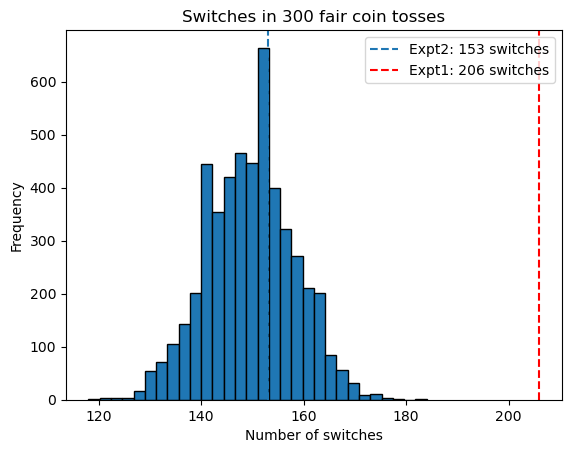

In [89]:
# Illustrate size of discrepancy

import numpy as np
import matplotlib.pyplot as plt

# set up parameters
n_tosses = 300
n_simulations = 5000

# simulate toss
tosses = np.random.randint(0,2, (n_simulations, n_tosses))

# count switches
switches = np.sum(tosses[:,1:] != tosses[:, :-1], axis=1)

# visualise
plt.hist(switches, bins=30, edgecolor="black")
plt.axvline(153, linestyle="--",
            label="Expt2: 153 switches")
plt.axvline(206, linestyle="--", color="red",
            label="Expt1: 206 switches")

plt.xlabel("Number of switches")
plt.ylabel("Frequency")
plt.title("Switches in 300 fair coin tosses")
plt.legend()
plt.show()

From the plot above, it is obvious that experiment 1 has had some meddling with it! This "expected value" in switching has been applied in watermarking AI text. A company that trains an AI can introduce specific rules that control which words follow each other in generated text, introducing a slight bias in sequential vocabulary. In this way, you can determine if a given text was generated by an AI (conditional on the watermark being available for comparison). For more info check out [Kirchenbauer et al (2023)](https://arxiv.org/abs/2301.10226).